# Day 2 — Estimating the room, and finding oneself in it

**The challenge, stage 1.** Yesterday the robot knew its pose, and we told it which points were
the wall's. Today it knows neither. It must:

- **A. Acquire the room.** Find the room's walls in a scan, with no labels and no map.
- **B. Localise against it.** Drive, and keep a calibrated belief about its own pose.
- **C. Meet the room's symmetry.** Find the place where gradient descent cannot help.
- **D. Hit the common-mode ceiling.** See how little a thousand points teach when they share one
  error.

The thesis calls A the **acquisition** regime, where the room is a variable, and B the
**operating** regime, where the room is a constant. Part E says why the split matters.

In [1]:
import sys
from pathlib import Path

LABS = Path.cwd() if (Path.cwd() / "toyworld").exists() else Path.cwd().parent
sys.path.insert(0, str(LABS))

import matplotlib.pyplot as plt
import numpy as np

from toyworld import Gaussian, Lidar, Robot, draw, laplace, se2, two_room_apartment
from toyworld.geometry import distance_to_polygon, polygon_area, polygon_iou
from toyworld.robot import Body, predict

rng = np.random.default_rng(0)
world = two_room_apartment()
lidar = Lidar(n_beams=360, sigma=0.02, max_range=12.0)
SIGMA = 0.02

## A. Acquiring the room

### A1. Whose frame?

The robot has no map, so there is no "world" frame it could report a pose in. The only frame
available is its own frame at the moment it starts. That choice is a **gauge**: a convention
that no measurement could ever fix, because the data would be identical in any other frame.
From here on, the **map frame is the robot's frame at t = 0**. The true starting pose `TRUE0`
is used only for grading.

Text(0.5, 1.0, 'what the robot has: one scan, in its own frame')

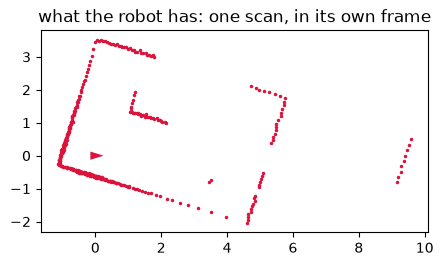

In [2]:
TRUE0 = np.array([1.0, 0.6, 0.3])       # ground truth, for grading only
scan0 = lidar.scan(world, TRUE0, rng)
P0 = scan0.points()                      # robot frame at t=0  ==  map frame

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(P0[:, 0], P0[:, 1], ".", ms=3, color="crimson")
draw.robot([0, 0, 0], ax)
ax.set_aspect("equal"); ax.set_title("what the robot has: one scan, in its own frame")

### A2. Which way is the room?

Rooms are mostly rectilinear. Each scan point has a local surface normal, which you can estimate
from its neighbours. If the room has a dominant direction $\theta_0$, every normal is
$\theta_0 + k\pi/2$ for some $k$. Multiplying the angle by 4 maps all four of those onto the same
angle, $4\theta_0$, so a **circular mean of $4\varphi_i$** votes for the room's direction without
knowing which wall each point is on.

**Exercise 1.** Compute $\theta_0 = \tfrac14 \arg \sum_i e^{4 i \varphi_i}$ from the normals
provided.

In [3]:
def scan_normals(P, max_gap=0.3):
    """Normal angle at each point, from its angular neighbours. `ok` is False across depth jumps."""
    order = np.argsort(np.arctan2(P[:, 1], P[:, 0]))
    Q = P[order]
    tangent = np.roll(Q, -1, axis=0) - np.roll(Q, 1, axis=0)
    ok = np.linalg.norm(tangent, axis=1) < max_gap
    phi = np.arctan2(tangent[:, 1], tangent[:, 0]) + np.pi / 2
    return Q, phi, ok


Q0, phi0, ok0 = scan_normals(P0)
theta0 = np.angle(np.sum(np.exp(4j * phi0[ok0]))) / 4
print(f"theta0 = {np.degrees(theta0):.2f}°   (truth, for grading: the room axes sit at "
      f"{np.degrees(se2.wrap(-TRUE0[2])):.2f}° mod 90° in the robot frame)")

theta0 = -17.19°   (truth, for grading: the room axes sit at -17.19° mod 90° in the robot frame)


**Question.** The thesis found that this direction must be **voted over all frames**, never taken
from the first scan. Why might the first scan be a bad place to take a gauge from?

*Answer.* The first scan is one noisy, partial view. If it happens to see mostly one wall, or a
piece of oblique furniture, $\theta_0$ is biased, and every wall's Manhattan class inherits that
bias. Worse, nothing downstream can correct it: a frame is part of an estimator's *output*, so a
wrong frame makes a good fit look like a wrong shape. (Memory note: the estimator's frame is
part of its return value. A fit with area 23.88 against 24.00 true, but aspect 1.344 against
1.500, was a frame error, not a fit error.)

### A3. Which points belong to a wall? A band that is derived, not chosen

A point belongs to a line when the line explains it better than clutter does. Clutter is uniform
over the scan's area $A$. A wall concentrates its points in a strip $L$ long and about $\sigma$
wide. The density ratio for a point at distance $r$ from the line is

$$ \frac{p_\text{wall}}{p_\text{clutter}} = \frac{A}{L\sqrt{2\pi}\,\sigma}\, e^{-r^2/2\sigma^2}. $$

The point is an inlier when this ratio exceeds 1, and it brings $\ln$(ratio) nats of evidence.

**Exercise 2.** Write the band half-width $r_\text{max}$ (where the ratio equals 1) and the
evidence per point, $\mathrm{gain}(r)$. Evaluate both for $A$ = the scan's bounding area,
$L = 4$ m and $\sigma = 2$ cm. Then plot $r_\text{max}$ against $L$ from 0.5 to 20 m.

A = 59.6 m²;  L = 4 m:  band = ±6.7 cm = 3.37 σ;  a point on the line brings 5.69 nats


Text(0.5, 1.0, 'a longer wall must fit each point more closely')

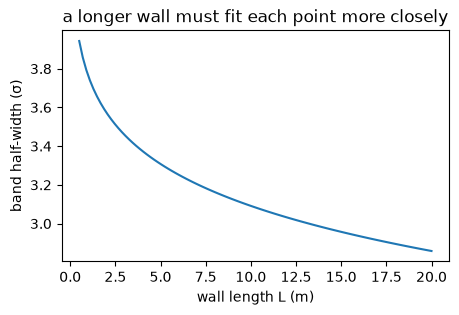

In [4]:
A_scan = np.ptp(P0[:, 0]) * np.ptp(P0[:, 1])


def band_halfwidth(A, L, sigma=SIGMA):
    return np.sqrt(2 * sigma ** 2 * np.log(A / (L * np.sqrt(2 * np.pi) * sigma)))


def gain(r, A, L, sigma=SIGMA):
    """Nats of evidence a point at distance r brings to the line (negative: clutter explains it better)."""
    return np.log(A / (L * np.sqrt(2 * np.pi) * sigma)) - r ** 2 / (2 * sigma ** 2)


print(f"A = {A_scan:.1f} m²;  L = 4 m:  band = ±{band_halfwidth(A_scan, 4.0) * 100:.1f} cm "
      f"= {band_halfwidth(A_scan, 4.0) / SIGMA:.2f} σ;  a point on the line brings {gain(0, A_scan, 4.0):.2f} nats")
Ls = np.linspace(0.5, 20, 100)
plt.figure(figsize=(5, 3))
plt.plot(Ls, band_halfwidth(A_scan, Ls) / SIGMA)
plt.xlabel("wall length L (m)"); plt.ylabel("band half-width (σ)")
plt.title("a longer wall must fit each point more closely")

The band comes out at about $3\sigma$, close to what anyone would have picked by hand. The
derivation adds two things a tuned constant cannot:
- the band **narrows as $L$ grows**, because a long wall is a more expensive explanation of any
  one point;
- each point arrives with its evidence in **nats**, the currency every structural decision will
  be priced in.

### A4. Four walls

**Exercise 3.** For each Manhattan class $k = 0..3$, with normal angle $a_k = \theta_0 + k\pi/2$:
1. initialise $d_k$ as the median of $n(a_k)^\top p$ over the points whose normal is within 15° of
   $\pm a_k$ and which lie in front of the robot ($n^\top p > 0$);
2. refine $(\alpha, d)$ with a Laplace fit in which every point is weighted by its
   **responsibility** $w = \rho/(1+\rho)$, where $\rho$ is the density ratio. A point with weight
   $w$ enters with standard deviation $\sigma/\sqrt{w}$. Re-weight and refit a few times.

In [5]:
def line_residual(P):
    return lambda th: np.cos(th[0]) * P[:, 0] + np.sin(th[0]) * P[:, 1] - th[1]


def fit_wall(P, alpha, d, A, iters=5):
    L = 4.0
    for _ in range(iters):
        r = line_residual(P)([alpha, d])
        rho = A / (L * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
        w = rho / (1 + rho)
        use = w > 1e-3
        fit = laplace(line_residual(P[use]), [alpha, d], SIGMA / np.sqrt(w[use]))
        alpha, d = fit.belief.mu
        inl = P[w > 0.5]
        along = inl @ np.array([-np.sin(alpha), np.cos(alpha)])
        L = max(np.ptp(along), 0.5) if len(inl) > 2 else L   # the wall's observed length
    return fit.belief, w


walls = []
for k in range(4):
    a = theta0 + k * np.pi / 2
    n = np.array([np.cos(a), np.sin(a)])
    proj = Q0 @ n
    same_class = ok0 & (np.abs(se2.wrap(2 * (phi0 - a))) < np.deg2rad(30)) & (proj > 0)
    d0 = np.median(proj[same_class])
    belief, w = fit_wall(Q0, a, d0, A_scan)
    walls.append(belief)
    print(f"wall {k}: alpha = {np.degrees(belief.mu[0]):8.3f}° ± {np.degrees(belief.sd[0]):.3f}°,"
          f"  d = {belief.mu[1]:.3f} ± {belief.sd[1] * 1000:.1f} mm,  inliers {int((w > 0.5).sum())}")

wall 0: alpha =  -17.170° ± 0.157°,  d = 5.001 ± 5.0 mm,  inliers 31
wall 1: alpha =   72.800° ± 0.098°,  d = 3.400 ± 3.5 mm,  inliers 39
wall 2: alpha =  162.801° ± 0.119°,  d = 0.998 ± 2.3 mm,  inliers 107
wall 3: alpha =  252.821° ± 0.093°,  d = 0.601 ± 1.8 mm,  inliers 145


**Exercise 4.** The polygon is the walls intersected in cyclic order. Build it, map it into the
world with the grading-only `TRUE0`, and compute the IoU against the true living room.

IoU = 0.9939,  area 23.991 m² (truth 24)


Text(0.5, 1.0, 'the room, from one scan, in the map frame')

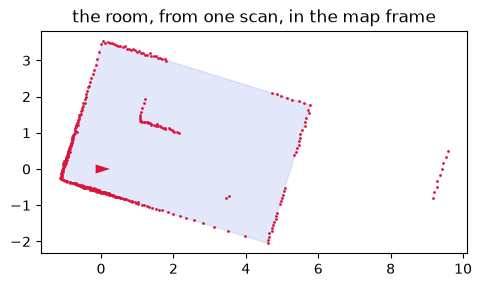

In [6]:
def intersect(w1, w2):
    A = np.array([[np.cos(w1.mu[0]), np.sin(w1.mu[0])], [np.cos(w2.mu[0]), np.sin(w2.mu[0])]])
    return np.linalg.solve(A, [w1.mu[1], w2.mu[1]])


room = np.array([intersect(walls[k], walls[(k + 1) % 4]) for k in range(4)])
truth_room = world.room("living").polygon
print(f"IoU = {polygon_iou(se2.transform_points(TRUE0, room), truth_room):.4f},  area {polygon_area(room):.3f} m² (truth 24)")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(Q0[:, 0], Q0[:, 1], ".", ms=2, color="crimson")
ax.fill(*np.vstack([room, room[:1]]).T, fc="royalblue", alpha=0.15, ec="royalblue")
draw.robot([0, 0, 0], ax); ax.set_aspect("equal"); ax.set_title("the room, from one scan, in the map frame")

### A5. The price of a shape

Real rooms are not always four walls. The thesis prices every extra edge by **minimum
description length**. To transmit an edge you must say which of the four Manhattan directions it
takes ($\ln 4$ nats), and where its offset lies among $2R/c$ distinguishable positions, with $R$
the sensor range and $c$ the resolution:

$$ L_\text{edge} = \ln 4 + \ln(2R/c). $$

**Exercise 5.** Compute $L_\text{edge}$ for $R = 12$ m and $c = 5$ cm. Then compute the evidence
the **table's south face** would bring if it were proposed as a wall: the sum of `gain(r)` over the
points on it (use the true labels this once). Does the MDL price stop the table from becoming a
wall?

In [7]:
L_edge = np.log(4) + np.log(2 * 12.0 / 0.05)
table_pts = P0[scan0.labels[scan0.hit] == "table"]
face = laplace(line_residual(table_pts), [theta0 + np.pi / 2, np.median(table_pts @ [-np.sin(theta0), np.cos(theta0)])], SIGMA)
r_face = line_residual(table_pts)(face.belief.mu)
evidence = gain(r_face, A_scan, 1.2).clip(min=0).sum()
print(f"L_edge = {L_edge:.2f} nats;  the table face would earn {evidence:.0f} nats from {len(table_pts)} points")

L_edge = 7.56 nats;  the table face would earn 82 nats from 34 points


**Question.** The table face pays the MDL price many times over, so the price cannot be what
keeps furniture out of the room's outline. What evidence *does* tell a table face from a wall?

*Answer.* **Free space.** Beams pass beside and beyond the table and hit the real wall behind it,
so the region behind the "wall" is observed to be empty. A room is a region the robot can see
into, not just a set of surfaces. That is why the thesis keeps two evidence channels (face
evidence and a free/occupied grid) and charges free space both ways: area claimed but never swept,
and area swept but not claimed. The robot's latest estimator goes further and builds the layout
*from* the swept free space (post-thesis, work in progress).

## B. Localising in the room you just built

Now the room is a constant (the operating regime) and the robot drives. Each step has two
parts:
- **Predict.** `predict(belief, odometry)` pushes the encoder and gyro noise through the motion
  Jacobian. No constant process noise is added.
- **Correct.** A Laplace fit of the scan against the room, with the prediction as the prior. The
  residual of each scan point is its distance to the nearest wall: the localiser's
  distance field.

**Exercise 6.** Write the pose residual: map the robot-frame points through a candidate pose $X$,
then take their distance to the polygon.

rms error: x 2.2 mm, y 1.0 mm, theta 0.036°


Text(0.5, 1.0, 'localising against the estimated room (ellipses ×20)')

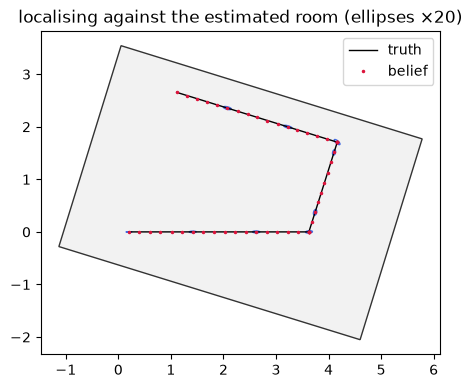

In [8]:
def pose_residual(P_robot, polygon):
    return lambda X: distance_to_polygon(se2.transform_points(X, P_robot), polygon)


def localise(prior, P_robot, polygon, iters=3):
    A, x = polygon_area(polygon), prior.mu.copy()
    for _ in range(iters):
        r = pose_residual(P_robot, polygon)(x)
        rho = A / (20.0 * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
        w = rho / (1 + rho)
        use = w > 1e-3
        fit = laplace(pose_residual(P_robot[use], polygon), x, SIGMA / np.sqrt(w[use]), prior=prior)
        x = fit.belief.mu
    return fit.belief


turn_to_north = [(0.0, (np.pi / 2 - 0.3) / 2.5)] * 5
turn_left = [(0.0, np.pi / 6)] * 6
COMMANDS = [(0.4, 0.0)] * 18 + turn_to_north + [(0.4, 0.0)] * 9 + turn_left + [(0.4, 0.0)] * 16


def drive(polygon, seed, commands=COMMANDS, scans=True):
    """Run the filter along the route. Returns the true poses (map frame) and the beliefs."""
    r = np.random.default_rng(seed)
    robot = Robot(TRUE0.copy(), Body(), r)
    belief = Gaussian([0, 0, 0], np.diag([1e-9] * 3))
    truths, beliefs = [], []
    for v, w in commands:
        belief = predict(belief, robot.step(v, w, 0.5))
        assert world.room_of(robot.pose[:2]) == "living", "the route left the room!"
        if scans:
            belief = localise(belief, lidar.scan(world, robot.pose, r).points(), polygon)
        truths.append(se2.ominus(robot.pose, TRUE0))
        beliefs.append(belief)
    return np.array(truths), beliefs


def nees(truths, beliefs):
    out = []
    for t, b in zip(truths, beliefs):
        e = t - b.mu
        e[2] = se2.wrap(e[2])
        out.append(e @ np.linalg.solve(b.Sigma, e))
    return np.array(out)


truths, beliefs = drive(room, seed=1)
err = np.array([t - b.mu for t, b in zip(truths, beliefs)])
print(f"rms error: x {np.sqrt((err[:, 0] ** 2).mean()) * 1000:.1f} mm, y {np.sqrt((err[:, 1] ** 2).mean()) * 1000:.1f} mm, "
      f"theta {np.degrees(np.sqrt((err[:, 2] ** 2).mean())):.3f}°")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.fill(*np.vstack([room, room[:1]]).T, fc="0.95", ec="0.2")
ax.plot(truths[:, 0], truths[:, 1], "k-", lw=1, label="truth")
mus = np.array([b.mu for b in beliefs])
ax.plot(mus[:, 0], mus[:, 1], ".", color="crimson", ms=3, label="belief")
for b in beliefs[::6]:
    draw.covariance(b.mu, b.Sigma * 400, ax)   # 2σ ellipses, ×20 so they are visible
ax.set_aspect("equal"); ax.legend(); ax.set_title("localising against the estimated room (ellipses ×20)")

**Is the belief honest?** The normalised estimation error squared (NEES),
$e^\top\Sigma^{-1}e$, averages to the state dimension (3) when the covariance is right. It is
larger when the belief is over-confident, and smaller when it is pessimistic.

**Exercise 7.** Compute the mean NEES over 4 seeds for three maps:
- the true polygon;
- the one-scan estimate from Part A;
- the true polygon with its east wall moved 1.5 cm.

In [9]:
true_room = se2.to_frame(TRUE0, truth_room)
bad_room = true_room.copy()
east = np.argsort(true_room @ np.array([np.cos(-0.3), np.sin(-0.3)]))[-2:]   # the two east corners
bad_room[east] += 0.015 * np.array([np.cos(-0.3), np.sin(-0.3)])
for name, poly in (("true room", true_room), ("estimated (part A)", room), ("east wall +1.5 cm", bad_room)):
    score = np.mean([nees(*drive(poly, seed)).mean() for seed in range(4)])
    print(f"{name:20s} mean NEES = {score:6.2f}   (3 = honest)")

true room            mean NEES =   1.95   (3 = honest)


estimated (part A)   mean NEES =   3.81   (3 = honest)


east wall +1.5 cm    mean NEES =  89.84   (3 = honest)


**Lesson.** A wall 1.5 cm out of place makes the localiser **confidently wrong**: its error
grows to several of its own standard deviations, and nothing inside the localiser notices. The
polygon is a *constant* in the operating regime. It contributes no uncertainty, so its errors are
shared by every scan, forever. That is the price of the regime split, and it is why the thesis
says the operating regime "cannot detect that the polygon it was given is wrong". Something
else, the acquisition regime, must be right, or know when it is not.

## C. The room's symmetry

A 6 × 4 m rectangle looks the same after a half-turn about its centre. Take the robot's final
scan and evaluate the Laplace free energy at the true pose and at its half-turn image, with a weak
prior and no odometry.

**Exercise 8.** Compute both $F$ values.

In [10]:
r_ = np.random.default_rng(7)
X_true = truths[-1]
P_last = lidar.scan(world, se2.compose(TRUE0, X_true), r_).points()
centre = true_room.mean(axis=0)
X_flip = np.array([*(2 * centre - X_true[:2]), se2.wrap(X_true[2] + np.pi)])
for name, X0 in (("true pose", X_true), ("half-turn", X_flip)):
    b = localise(Gaussian(X0, np.diag([1.0, 1.0, 1.0])), P_last, true_room)
    r = pose_residual(P_last, true_room)(b.mu)
    rho = polygon_area(true_room) / (20 * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
    w = rho / (1 + rho)
    F = laplace(pose_residual(P_last[w > 1e-3], true_room), b.mu, SIGMA / np.sqrt(w[w > 1e-3]),
                prior=Gaussian(X0, np.eye(3))).free_energy
    print(f"{name:10s} pose {np.round(b.mu, 3)}   F = {F:.2f} nats")

true pose  pose [1.11  2.657 2.84 ]   F = -786.82 nats
half-turn  pose [ 3.539 -1.164 -0.302]   F = -786.82 nats


**Questions.**
- The two free energies differ by a fraction of a nat. No gradient connects the two poses, so
  descent cannot choose between them. What must?
- The table and the door gap are *not* symmetric. Why don't they break the tie here?

*Answers.*
- The choice is **discrete**, so it needs a discrete search plus evidence the room cannot
  provide: continuity with the previous pose (the motion prior), or a landmark that is not
  symmetric. The thesis's localiser searches the room's symmetries explicitly. That is one of the
  few places where a threshold is the right design, because a continuous relaxation of a
  discrete choice is not a better model of it.
- Because the **model** does not contain them. Our polygon has no door gap, and the table's
  points are classed as clutter. Evidence the model throws away cannot break a tie. The thesis
  later uses the fridge as a room landmark for exactly this purpose.

## D. The common-mode ceiling

Before there is a room to localise against, the robot only has odometry, and its pose
uncertainty grows. Suppose it maps the **table's south face** from there, using a dense sensor
(think: a camera mask with thousands of pixels). Each point's map position is
$p_\text{map} = X \oplus p_\text{robot}$, so every point inherits the **same** pose error.

Marginalising that shared error gives the information one frame can carry:

$$ \mathcal I = J^\top(\sigma^2 I + J_X\Sigma_X J_X^\top)^{-1}J
   \;\overset{\text{Woodbury}}{\Longrightarrow}\;
   \operatorname{var}(\hat y) = \frac{\sigma^2}{N} + j^\top \Sigma_X\, j
   \;\xrightarrow[N\to\infty]{}\; j^\top\Sigma_X j \neq 0, $$

where $j = \partial y_\text{map} / \partial X$, averaged over the points.

**Exercise 9.** Over 60 runs, dead-reckon the first leg, estimate the face's offset along its normal from
$N$ = 1 … 32 points, and compare the true rms error with two predictions: independent points
only (with Day 1's per-point $\sigma_i = \sigma|u_i^\top n|$), and the Woodbury formula.

N=  1  actual   8.82 mm   independent   4.92   Woodbury   9.29
N=  2  actual   7.44 mm   independent   3.54   Woodbury   8.47
N=  4  actual   7.49 mm   independent   2.50   Woodbury   8.02
N=  8  actual   7.15 mm   independent   1.78   Woodbury   7.74
N= 16  actual   6.69 mm   independent   1.25   Woodbury   7.64
N= 32  actual   6.57 mm   independent   0.89   Woodbury   7.58


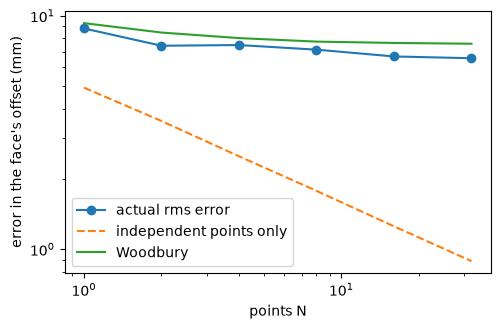

In [11]:
dense = Lidar(n_beams=2880, sigma=SIGMA)
Ns = [1, 2, 4, 8, 16, 32]
rows = {N: [] for N in Ns}
for seed in range(60):
    r_ = np.random.default_rng(seed)
    _, bs = drive(true_room, seed, COMMANDS[:18], scans=False)   # odometry only
    b = bs[-1]
    robot_pose = se2.compose(TRUE0, _[-1])
    s = dense.scan(world, robot_pose, r_)
    on_table = s.labels[s.hit] == "table"
    true_pts = np.stack([np.cos(s.angles), np.sin(s.angles)], 1)[s.hit] * s.true_ranges[s.hit, None]
    on_face = on_table & (np.abs(se2.transform_points(robot_pose, true_pts)[:, 1] - 2.2) < 1e-6)  # grading
    P_face = s.points()[on_face]
    for N in Ns:
        idx = r_.choice(len(P_face), N, replace=False)
        pts_map = se2.transform_points(b.mu, P_face[idx])
        n_face = np.array([-np.sin(-0.3), np.cos(-0.3)])             # the face's normal, map frame
        d_true = se2.to_frame(TRUE0, np.array([[2.2, 2.2]]))[0] @ n_face
        err = (pts_map @ n_face).mean() - d_true                     # what the robot would report, minus truth
        th = b.mu[2]
        dp_dth = np.stack([-np.sin(th) * P_face[idx, 0] - np.cos(th) * P_face[idx, 1],
                           np.cos(th) * P_face[idx, 0] - np.sin(th) * P_face[idx, 1]], 1)
        j = np.array([n_face[0], n_face[1], (dp_dth @ n_face).mean()])  # ∂(offset)/∂(x, y, θ)
        u = P_face[idx] / np.linalg.norm(P_face[idx], axis=1, keepdims=True)     # beam directions, robot frame
        u_map = u @ se2.rot(th).T
        sig_i = SIGMA * np.abs(u_map @ n_face)                       # Day 1: noise along the beam, seen along the normal
        var_indep = np.sum(sig_i ** 2) / N ** 2
        rows[N].append((err, np.sqrt(var_indep), np.sqrt(var_indep + j @ b.Sigma @ j)))

rms = [np.sqrt(np.mean([e ** 2 for e, _, _ in rows[N]])) for N in Ns]
naive = [np.mean([n for _, n, _ in rows[N]]) for N in Ns]
wood = [np.mean([w for _, _, w in rows[N]]) for N in Ns]
plt.figure(figsize=(5.5, 3.4))
plt.loglog(Ns, np.array(rms) * 1000, "o-", label="actual rms error")
plt.loglog(Ns, np.array(naive) * 1000, "--", label="independent points only")
plt.loglog(Ns, np.array(wood) * 1000, "-", label="Woodbury")
plt.xlabel("points N"); plt.ylabel("error in the face's offset (mm)"); plt.legend()
for N, a, n_, w_ in zip(Ns, rms, naive, wood):
    print(f"N={N:3d}  actual {a * 1000:6.2f} mm   independent {n_ * 1000:6.2f}   Woodbury {w_ * 1000:6.2f}")

**Lesson.** Past a handful of points, more pixels buy nothing: the error stops at the pose
error, not at zero. A filter that kept counting points as independent would report
under a millimetre while being off by about seven. That is the over-confidence every concept agent in
the thesis must guard against, and the reason the agents carry this term explicitly.

## E. Why the two regimes are kept apart

You have now run both regimes. A natural question is why not estimate the room and the pose
together all the time, as SLAM does. The thesis answers that a room changes over years and a pose
changes every cycle. Estimating them jointly at frame rate tracks a constant at great expense. So
the room is estimated jointly only until it is settled, and then handed over as a constant.

The robot's latest results (post-thesis, work in progress) sharpen the hand-over. While the room
is still being estimated, registering the pose against the **provisional** layout let the
layout's mistakes drag the pose, and the dragged pose corrupted the layout. Taking the pose from
plain scan-to-map SLAM instead, and building the layout from the aligned map, gave millimetre
poses and a layout that matched the truth to IoU ≈ 0.96 within a minute.
Exercise 7 is the small version of that lesson: **a factor inherits the errors of whatever it is
estimated through.**